![banner-pdi](https://user-images.githubusercontent.com/58775072/141189378-b5df3287-e8c0-48a1-ad11-825ba317463b.png)

## Universidade Federal de Campina Grande (UFCG)
## Centro de Engenharia Elétrica e Informática (CEEI) 
## Disciplina: Int. ao Processamento de Imagem Digital e Visão Computacional
## Professora: Luciana Ribeiro Veloso
## Aluno(a): Coloque seu nome aqui

## Observações
***

1. Os arquivos de laboratório devem ser salvos seguindo o seguinte padrão: `lab-x-nome-sobrenome.ipynb`.
2. Não esqueça de colocar o seu nome no cabeçalho acima.
3. Não altere a ordem das células e realize as implementações somente nos campos específicados.  
4. Ao longo do laboratório será solicitado perguntas teóricas relativas aos assuntos das aulas da disciplina e implementações de código utilizando a linguagem de programação Python. 
5. As células de implementação com código serão indicadas pelos seguintes comentários: `# IMPLEMENTE O SEU CÓDIGO AQUI`.
6. Para editar uma célula de texto, basta clicar duas vezes com o cursos do mouse para editar, e `Ctrl + Enter` para finalizar a edição. 
7. Para rodar as células com os códigos desenvolvidos, digite `Ctrl + Enter` ou clique em `Run` no menu do Jupyter.
8. Dúvidas, problemas de execução de código ou dificuldades com a linguagem de programação Python devem ser feitas durante as aulas de laboratório, encaminhadas para o grupo de WhatsApp da turma ou fórum do PVAE da disciplina.
9. Os laboratórios devem ser enviados nos campos especificados pelo PVAE. ATENTE-SE AOS PRAZOS DE ENTREGA!

# <span style='color:red'>Laboratório 6: Redes Neurais Artificiais</span>
***

### Importação dos Pacotes

In [16]:
import os                                                 # operational system para manipulação de arquivos.
import cv2                                                # openCV para manipulação de imagens.
import numpy as np                                        # numpy para manipulação de matrizes e arrays.
import matplotlib.pyplot as plt                           # pyplot para plotagem de gráficos e imagens.
from sklearn.model_selection import train_test_split      # função para particionamento dos dados
from tensorflow.keras.models import Sequential            # classe de modelos sequenciais para construir as redes neurais.
from tensorflow.keras.layers import Dense, Input, Dropout # camada de neurônios densamente conectados.
from tensorflow.keras.optimizers import SGD               # otimizador "Descida do Gradiente com Momento".
from tensorflow.keras.datasets import boston_housing      # dataset utilizado nesse experimento.

### Banco de Dados
* Vamos utilizar um banco de dados do catálogo de datasets do Keras, que é disponibilizado como uma função pronta;

* Cada instância do banco de dados corresponde a um conjunto de 13 valores referentes a características de subúrbios de Boston na década de 1970, a exemplo de taxa de crimes, imposto sobre propriedade, etc;

* Esses valores serão utilizados para calcular o valor mediano das residências no respectivo subúrbio em um problema de regressão, de modo que iremos mapear um vetor de entrada com 13 valores em um vetor de saída com 1 único elemento;

* O banco de dados contém 506 valores divididos em 404 instâncias de treino e 102 de teste;

* Uma descrição mais detalhada dos valores de entrada pode ser vista em http://lib.stat.cmu.edu/datasets/boston, onde os valores são descritos na ordem que aparecem;

### Organização do banco de dados

* Comumente os dados utilizados no treinamento de modelos de inteligência artificial reservam a primeira dimensão para controlar a amostra e espalham o tipo de dado utilizado nas demais dimensões do tensor. 


* Nesse caso, os nossos dados são vetores de características unidimensionais (1D), de modo que são organizados em tensores bidimensionais (2D) com formato: **dados.shape = (amostras, características)**
    * O i-ésimo exemplo pode ser acessado a partir de: **exemplo = dados[i]**
    * A j-ésima característica dos exemplos pode ser acessada a partir de: **caracteristica = dados[:, j]**
    * Porções do tensor podem ser acessadas utilizando fatiamento, por exemplo:
        * primeiros_5_exemplos = dados[:5]
        * caracteristicas_9a13 = dados[i, 8:13]
        

* Lembrem-se que a contagem de índices em Python começa em 0 e só é inclusiva no primeiro elemento:
    * **:5** produz os índices **0, 1, 2, 3, 4** 
    * **8:13** produz os índices **8, 9, 10, 11, 12** 
        

* O banco de dados pode ser carregado utilizando:
    * **(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()**
    * train_data é um tensor com as entradas do conjunto de treino;
    * test_data é um tensor com as entradas do conjunto de teste;
    * train_targets é um tensor com os gabaritos do conjunto de treino;
    * test_targets é um tensor com os gabaritos do conjunto de teste;

## <span style='color:blue'>Questão 1: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* (a) O código abaixo carrega o banco de dados, acesse alguns exemplos de treinamento e de teste e veja suas dimensões.
    * Use índices entre **[0, 404]** para os dados de treino e entre **[0, 102]** para os de teste.

* (b) Verifique as dimensões e as faixas de valores de cada característica nos vetores de entrada dos conjuntos de treino e de teste. A faixa de valores das características são semelhantes? E os dados de treino e de teste?**</span>
    * Encontre os valores mínimo/máximo além da média **(np.mean)** e da variância **(np.var)** de cada uma das 13 características.
    * Sugestão: leia sobre o parâmetro "axis" na documentação das funções **np.min**, **np.max** e **np.mean**.
* (c) Verifique as dimensões e as faixas de valores dos gabaritos dos conjuntos de treino e de teste. Os valores encontrados são semelhantes?

In [2]:
(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

65536/57026 [==================================] - 0s 2us/step


In [3]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 1 - letra (a)

|**Características dos Dados de Entrada**|**Descrição**|
|:-:|:-|
|**CRIM**|     <span style='color:red'>per capita crime rate by town</span>|
|**ZN**|       <span style='color:red'>proportion of residential land zoned for lots over 25,000 sq.ft.</span>|
|**INDUS**|    <span style='color:red'>proportion of non-retail business acres per town</span>|
|**CHAS**|     <span style='color:red'>Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)</span>|
|**NOX**|      <span style='color:red'>nitric oxides concentration (parts per 10 million)</span>|
|**RM**|       <span style='color:red'>average number of rooms per dwelling</span>|
|**AGE**|      <span style='color:red'>proportion of owner-occupied units built prior to 1940</span>|
|**DIS**|      <span style='color:red'>weighted distances to five Boston employment centres</span>|
|**RAD**|      <span style='color:red'>index of accessibility to radial highways</span>|
|**TAX**|      <span style='color:red'>full-value property-tax rate per \$10,000</span>|
|**PTRATIO**|  <span style='color:red'>pupil-teacher ratio by town</span>|
|**B**|        <span style='color:red'>$1000(B_k - 0.63)^2$ where Bk is the proportion of blacks by town</span>|
|**LSTAT**|    <span style='color:red'>\% lower status of the population</span>|

|**Características dos Dados de Saída**|**Descrição**|
|:-:|:-|
|**MEDV**|     <span style='color:red'>Median value of owner-occupied homes in \$1000's</span>|

In [4]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 1 - letra (b)

In [5]:
# IMPLEMENTE SEU CÓDIGO AQUI -QUESTÃO 1 - letra (c)

## <span style='color:green'>Respostas da Questão 1:</span>

* (a) Adicione suas respostas aqui.
* (b) Adicione suas respostas aqui.
* (c) Adicione suas respostas aqui.

### Pre-processamento dos dados

* Dados cujas características assumem diferentes faixas de valores muitas vezes são problemáticos para o aprendizado dos modelos e podem reduzir a velocidade de convergência ou até mesmo limitar as capacidades do modelo final.

* Nesse sentido, uma prática comum é a normalização dos dados antes do treinamento, que geralmente é feito por característica em forma da subtração da média e divisão pelo desvio padrão, o que faz com que os dados resultantes tenham média 0 e variância 1.

* Um ponto muito importante é que a normalização deve ser feita partir dos mesmos valores em todos os conjuntos, ou seja, os dados são normalizados segundo informações do conjunto de treino.

* Na prática não temos como calcular a média e variância real, mas se os dados de treino são significativos os seus valores são suficientes.

In [6]:
# Calcula a média do conjunto de treino
mean = train_data.mean(axis = 0)
# Calcula o desvio padrão do conjunto de treino
std = train_data.std(axis = 0)
# Normaliza os dados de treino
train_data -= mean
train_data /= std
# Normaliza os dados de teste
test_data -= mean
test_data /= std

## <span style='color:blue'>Questão 2: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Repita o item b da primeira questão para os dados normalizados. O que se observa quantos aos valores de média e variância para os dados de treino e teste? Comente a sua interpretação sobre as diferenças observadas.

In [7]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 2

## <span style='color:green'>Resposta da Questão 2:</span>

* Adicione suas respostas aqui.

Agora vamos criar uma partição de validação a partir do conjunto de treino para realizar uma validação cruzada. Vamos utilizar a função **train_test_split**, que separa dados e os seus respectivos gabaritos segundo uma fração especificada.

In [8]:
# fração escolhida para separar o mesmo número de instâncias do conjunto de testes
data_frac = test_data.shape[0] / train_data.shape[0]

# criação do conjunto de validação
train_data, val_data, train_targets, val_targets = train_test_split(train_data,             # dados de treino
                                                                    train_targets,          # gabaritos de treino
                                                                    test_size = data_frac,  # proporção de dados p/ validação
                                                                    random_state = 42)      # semente de geração

print("Treino:", train_data.shape, train_targets.shape)
print("Validação:", val_data.shape, val_targets.shape)

Treino: (302, 13) (302,)
Validação: (102, 13) (102,)


### Construindo o modelo

Para construir o modelo usaremos a classe **Sequential**, que possibilita a construção de modelos sequenciais de forma bastante simples.
* A construção do modelo é feita a partir do seu instanciamento como objeto da classe seguido de chamadas à função **add()** para adicionar camadas.
* Como estamos construindo apenas Redes Neurais Artificiais por enquanto, vamos utilizar apenas as camadas **Dense** e **Input**.
    * A camada Input cria a entrada da rede com **Input(shape = None )**
        * shape corresponde ao formato do tensor de entrada, no nosso caso será o número de características do nosso banco de dados (13);
    * A camada Dense pode ser chamada com **Dense(n_unidades, activation = 'linear' )**
        * n_unidades corresponde ao número de neurônios da camada;
        * activation corresponde à função de ativação utilizada na camada;
* Algumas funções de ativação disponíveis são:
    * "linear"
    * "relu"
    * "sigmoid"
    * "softmax"
    * "tanh"


* Mais informações sobre a camada dense podem ser vistas em **https://keras.io/api/layers/core_layers/dense/**
* Mais informações sobre as ativações disponíveis podem ser vistas em **https://keras.io/api/layers/activations/**

## <span style='color:blue'>Questão 3: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* (a) A função abaixo constroi um modelo de rede neural e utiliza a função summary() para apresentar um resumo das informações da rede neural produzida. Comente o que faz cada linha do código.
    * (opcional) Modifique parâmetros como o número de unidades de cada camada e/ou o formato do tensor de entrada e/ou o número de saídas.
* (b) Explique como o número de parâmetros de cada camada é calculado.
* (c) Nesse caso utilizamos uma saída com ativação linear. Qual seria a desvantagem de utilizar esse tipo de ativação nas demais camadas?

In [9]:
# COMENTE AS LINHAS DE CÓDIGO AQUI --> QUESTÃO 3 -letra (a)
def build_model( n_inputs, n_outputs ):
    '''construção do modelo de rede neural convolucional'''
    
    rede = Sequential()
    rede.add( Dense(units = 64, activation = "relu", input_shape = (n_inputs,)))
    rede.add(Dense(units = 64, activation = "relu"))
    rede.add(Dense(units = n_outputs ))
    return rede

model = build_model(13, 1)
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                896       
                                                                 
 dense_1 (Dense)             (None, 64)                4160      
                                                                 
 dense_2 (Dense)             (None, 1)                 65        
                                                                 
Total params: 5,121
Trainable params: 5,121
Non-trainable params: 0
_________________________________________________________________


## <span style='color:green'>Respostas da Questão 3:</span>

* (b) Adicione suas respostas aqui.
* (c) Adicione suas respostas aqui.

Após a construção do modelo ele deve ser compilado antes que os parâmetros sejam treinados. Isso é feito utilizando a função **compile**:

* **model.compile( optimizer = opt, loss = fperdas, metrics = [] )** 
    * O optimizer é o algoritmo otimizador utilizado no lugar da descida do gradiente, o Keras oferece diversas opções;
        * Para treinar a partir da descida do gradiente utilizaremos o SGD (descida do gradiente com momento), mas setaremos esse parâmetro para 0.
        * **opt = SGD( learning_rate = taxa_de_aprendizagem, momentum = 0 )**
    * A função de perdas pode ser definida a partir do parâmetro loss, como este é um problema de regressão utilizaremos o erro médio quadrático: 
        * **loss = "mse"**
    * Podemos passar uma lista de métricas a serem computadas durante o treinamento, nesse caso utilizaremos o erro médio absoluto:
        * **metrics = ["mae"]**
        * Note que estamos passando uma lista com uma única métrica, mas outras poderiam ser adicionadas à lista.
         
         

* Algoritmos otimizadores populares são o Adam (**https://keras.io/api/optimizers/adam/**) e o RMSprop(**https://keras.io/api/optimizers/rmsprop/**)
* Mais informações sobre os otimizadores disponíveis podem ser vistas em **https://keras.io/api/optimizers/**
* Mais informações sobre as funções de perdas disponíveis podem ser vistas em **https://keras.io/api/losses/**
* Mais informações sobre as métricas disponíveis podem ser vistas em **https://keras.io/api/metrics/**



In [10]:
model = build_model(13, 1)
model.compile( optimizer = SGD(learning_rate = 0.001, momentum = 0.0), loss = "mse", metrics = ["mae"] )
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 64)                896       
                                                                 
 dense_4 (Dense)             (None, 64)                4160      
                                                                 
 dense_5 (Dense)             (None, 1)                 65        
                                                                 
Total params: 5,121
Trainable params: 5,121
Non-trainable params: 0
_________________________________________________________________


### Treinando o modelo

O treinamento é realizado a partir da função **fit**, que recebe dados de treino e de validação além de hiperparâmetros como o número de épocas e o tamanho dos lotes de dados (batchsize).

* **hist = model.fit(x = None, y = None, epochs = 1, batchsize = None, validation_data = None, verbose = "auto")**
    * x corresponde aos dados de treino;
    * y corresponde aos gabaritos de treino;
    * epochs corresponde ao número de épocas de treinamento;
    * batchsize corresponde ao tamanho dos lotes entregues à rede de cada vez;
    * validation_data corresponde a uma tupla ( val_data, val_targets ) com os dados de validação;
    * verbose indica como a função deve reportar os resultados:
        * 0: modo silencioso, nenhum retorno em formato de texto;
        * 1: retorno a cada época e barra de progresso;
        * 2: retorno a cada época sem barra de progresso;
    * hist é um dicionário de retorno com os valores de loss e das métricas computadas para treino e validação;

In [11]:
hist = model.fit(x = train_data, y = train_targets, epochs = 100, 
                 batch_size = 1, validation_data = ( val_data, val_targets ), 
                 verbose = 1)

Epoch 1/100
302/302 [==============================] - 1s 3ms/step - loss: 79.1715 - mae: 6.0144 - val_loss: 18.6169 - val_mae: 3.2626
Epoch 2/100
302/302 [==============================] - 1s 2ms/step - loss: 42.0576 - mae: 4.5262 - val_loss: 12.1675 - val_mae: 2.5509
Epoch 3/100
302/302 [==============================] - 1s 2ms/step - loss: 30.5149 - mae: 3.9703 - val_loss: 20.1924 - val_mae: 3.5302
Epoch 4/100
302/302 [==============================] - 1s 3ms/step - loss: 21.0674 - mae: 3.3233 - val_loss: 86.8045 - val_mae: 6.2710
Epoch 5/100
302/302 [==============================] - 1s 2ms/step - loss: 23.7069 - mae: 3.2979 - val_loss: 10.7016 - val_mae: 2.5401
Epoch 6/100
302/302 [==============================] - 1s 2ms/step - loss: 19.5858 - mae: 2.9941 - val_loss: 15.8381 - val_mae: 3.1959
Epoch 7/100
302/302 [==============================] - 1s 2ms/step - loss: 21.6955 - mae: 3.2567 - val_loss: 11.0864 - val_mae: 2.4879
Epoch 8/100
302/302 [==============================] - 

302/302 [==============================] - 0s 2ms/step - loss: 7.2011 - mae: 1.9963 - val_loss: 11.6077 - val_mae: 2.4896
Epoch 62/100
302/302 [==============================] - 1s 2ms/step - loss: 7.5458 - mae: 1.8819 - val_loss: 8.5399 - val_mae: 2.1744
Epoch 63/100
302/302 [==============================] - 0s 2ms/step - loss: 5.5403 - mae: 1.7401 - val_loss: 6.6808 - val_mae: 1.9007
Epoch 64/100
302/302 [==============================] - 1s 2ms/step - loss: 4.3996 - mae: 1.5864 - val_loss: 8.5926 - val_mae: 2.0803
Epoch 65/100
302/302 [==============================] - 0s 2ms/step - loss: 5.7420 - mae: 1.7795 - val_loss: 10.0733 - val_mae: 2.2531
Epoch 66/100
302/302 [==============================] - 1s 2ms/step - loss: 5.0100 - mae: 1.6437 - val_loss: 10.1143 - val_mae: 2.2784
Epoch 67/100
302/302 [==============================] - 1s 2ms/step - loss: 4.6354 - mae: 1.6006 - val_loss: 10.3404 - val_mae: 2.2863
Epoch 68/100
302/302 [==============================] - 1s 2ms/step - l

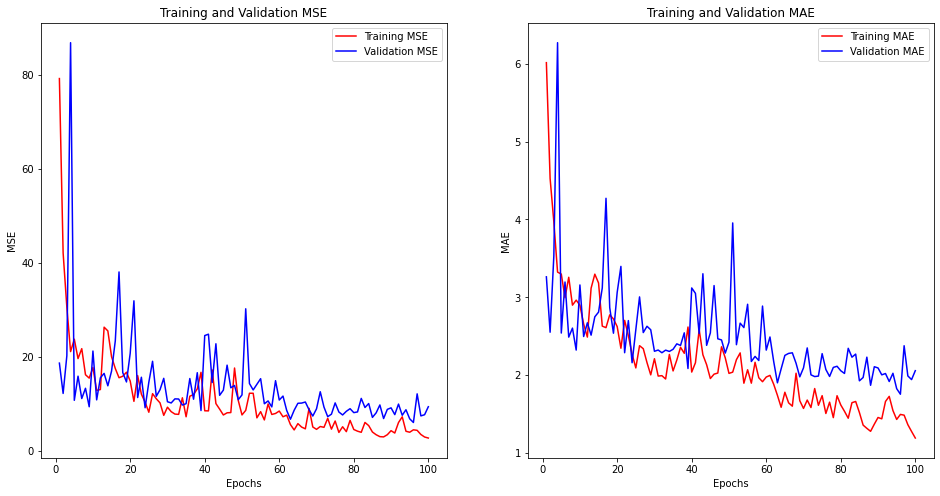

In [12]:
# plotando os resultados obtidos
fig, axes = plt.subplots(1, 2, squeeze = False, figsize = (16,8))

history_dict = hist.history

# loss - MSE
train_loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]

# epochs
epochs = range(1, len(train_loss_values) + 1)

# metrica - MAE
train_mae_values = history_dict["mae"]
val_mae_values = history_dict["val_mae"]

ax = axes.flat[0]
ax.plot(epochs, train_loss_values, "r", label = "Training MSE")
ax.plot(epochs, val_loss_values, "b", label = "Validation MSE")
ax.set_title("Training and Validation MSE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.legend()

ax = axes.flat[1]
ax.plot(epochs, train_mae_values, "r", label = "Training MAE")
ax.plot(epochs, val_mae_values, "b", label = "Validation MAE")
ax.set_title("Training and Validation MAE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MAE")
ax.legend()

## <span style='color:blue'>Questão 4: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* Comente os resultados obtidos nos gráficos acima. Houve overfitting? Se sim, o que pode ser feito para melhorar a qualidade do modelo?

## <span style='color:green'>Respostas da Questão 4:</span>

* Adicione suas respostas aqui.

## <span style='color:blue'>Questão 5: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* Modifique hiperparâmetros do modelo como o número de camadas, as funções de ativação, o número de épocas utilizadas e o tamanho dos lotes. Comente os resultados obtidos a partir das mudanças realizadas. Utilize várias células para dividir as etapas de construção dos modelos.

In [13]:
# IMPLEMENTE SEUS MODELOS AQUI --> QUESTÃO 5 (use várias células)

## <span style='color:green'>Respostas da Questão 5:</span>

* Adicione suas respostas aqui.

### Teste do modelo

O teste do modelo pode ser realizado a partir da função **evaluate**, que recebe os dados de treino e retorna o valor de loss calculado para esse conjunto e os valores de cada métrica da lista fornecida durante a compilação do modelo. 

* É uma prática comum realizar ajustes no modelo com base no conjunto de validação e só utilizar o conjunto de testes após a definição dos hiperparâmetros definitivos.
* Como os hiperparâmetros são ajustados a partir dos resultados obtidos para o conjunto de validação, o modelo pode acabar. sobreajustando aos dados de validação, então é interessante mudar os dados desse conjunto com frequência.
* Para mudar os dados de validação basta alterar a semente na função train_test_split.
* Crie um novo modelo do zero após a realização de mudanças nos conjuntos de treino/validação.

In [14]:
test_mse, test_mae = model.evaluate( test_data, test_targets)

# observa-se que os dados de saída são normalizados em milhares de dólares, 
# então é necessário multiplicar por 1000 para obter os valores absolutos
print("Erro médio absoluto de teste: ${:.2f}".format(1000*test_mae))

4/4 [==============================] - 0s 3ms/step - loss: 21.3462 - mae: 2.7959
Erro médio absoluto de teste: $2795.93


## <span style='color:blue'>Questão 6: [Valor da Questão: 1.0][Taxa de acerto: x.x]</span>

* Verifique novamente a faixa de valores dos gabaritos no banco de dados. Considerando a extensão dessa faixa de valores, pode-se dizer que as predições do modelo são significativas?

In [15]:
# IMPLEMENTE SEU CÓDIGO AQUI --> QUESTÃO 6

## <span style='color:green'>Resposta da Questão 6:</span>

* Adicione suas respostas aqui.

### Referências
* Chollet, Francois. Deep learning with Python. Simon and Schuster, 2017.

***
![image](https://user-images.githubusercontent.com/58775072/156389663-fcacd20e-8479-4596-b7c4-c438f39424b8.gif)